
# Predict whether a customer will leave a company (churn) based on customer information using Machine Learning.

**1. Importing Libraries and Dataset**\

Start by importing the necessary Python libraries and loading the Telco Customer Churn dataset. This dataset contains various customer details such as service plans, usage behavior and churn status

In [30]:
import pandas as pd
import numpy as ny
# give path
dataset=pd.read_csv('/content/sample_data/Telco-Customer-Churn-10000.csv')
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,8917-JIQWP,Male,0,No,Yes,70,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,114.60,7882.5,No
1,8177-HOFZP,Male,0,No,No,27,Yes,Yes,DSL,No,...,No,No,No,No,Month-to-month,No,Mailed check,49.00,1291.35,No
2,3777-IRVTR,Male,0,Yes,No,62,Yes,Yes,Fiber optic,Yes,...,No,No,No,Yes,One year,No,Electronic check,96.10,6001.45,No
3,1600-ZSGOD,Male,0,No,No,57,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),20.55,1252.85,No
4,9561-CUYKB,Female,0,Yes,Yes,26,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),20.25,493.95,No


**Understanding the Dataset**

to gain insight from data we first check missing values and understand its structure

In [31]:
print (dataset.isnull().sum())
print(dataset.describe())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
       SeniorCitizen        tenure  MonthlyCharges
count   10000.000000  10000.000000    10000.000000
mean        0.155400     32.520400       65.167375
std         0.362304     24.669176       30.109316
min         0.000000      0.000000       18.550000
25%         0.000000      9.000000       38.500000
50%         0.000000     29.000000       70.500000
75%         0.000000     56.000000       90.050000
max         1.000000     72.000000      118.750000


**tenure**– The number of months a customer has stayed with the company.

**InternetService** – The type of internet service the customer has DSL, Fiber optic or None.

**PaymentMethod**– The method the customer uses for payments.

**Churn** – The target variable i.e Yes for customer churned and No for customer stayed.

**Analyzing Churn Distribution**

check the number of churners and non-churners to understand the balance of the dataset.

Churn
No     7375
Yes    2625
Name: count, dtype: int64


/tmp/ipykernel_1285/1752709970.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=dataset, palette='coolwarm')


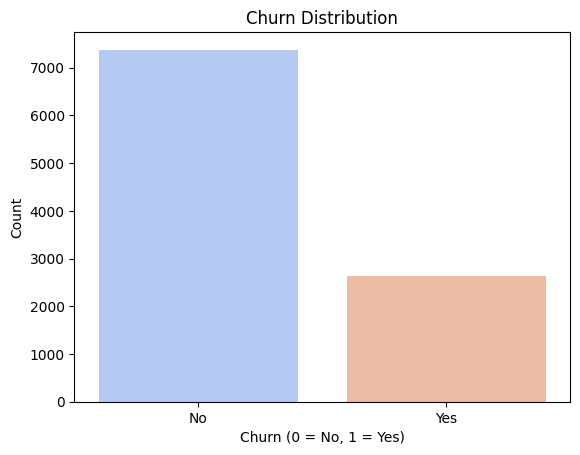

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
print(dataset['Churn'].value_counts())
sns.countplot(x='Churn', data=dataset, palette='coolwarm')
plt.title('Churn Distribution')
plt.xlabel('Churn (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()


Data Preprocessing

Handling Missing and Incorrect Values

Before processing we ensure that all numerical columns contain valid values. The TotalCharges column sometimes has empty spaces which need to be converted to numerical values.

In [33]:
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')
dataset['TotalCharges'].fillna(dataset['TotalCharges'].median(), inplace=True)

/tmp/ipykernel_1285/266048525.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['TotalCharges'].fillna(dataset['TotalCharges'].median(), inplace=True)


Handling Categorical Variables

mechine learnings model cant  understand text  so we need to convert text into numericial values

In [34]:
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
categorical_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService',
                    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
                    'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
for col in categorical_cols:
    dataset[col] = labelencoder.fit_transform(dataset[col])

Feature Selection and Splitting Data


Machine learning needs:

X = input data (features) 80%use

y = output data (target)20% use

Then we split it into:

Training data (to teach the model)

Testing data (to check the model)

In [35]:
from sklearn.model_selection import train_test_split
x = dataset.drop(['customerID','Churn'], axis=1)
y = dataset['Churn']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

**Feature Scaling**

Feature scaling is the process of transforming the values of input variables (features) so that they are on a similar scale or range. It is commonly used in machine learning and data analysis to improve the performance and convergence of algorithms.

Definition:
Feature scaling is a data preprocessing technique that adjusts the range or distribution of numerical features so that they contribute equally to a model during training.

In [36]:
from sklearn.preprocessing import StandardScaler


In [37]:
scaler= StandardScaler()
X_train =scaler.fit_transform(X_train)
X_test =scaler.transform(X_test)


Model Training and **Prediction**

Training means teaching the machine learning model using the training data so that it can learn patterns and relationships.

In [38]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier()
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

Model Evaluation – Accuracy **Score**

After training a machine learning model, we need to check how well it performs. This process is called model evaluation.

In [39]:

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accurasy{accuracy:.2f}")

Model Accurasy0.93


Confusion Matrix and Performance **Metrics**

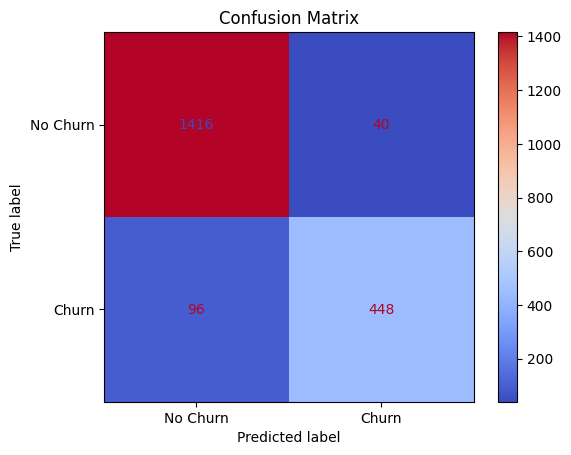

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
disp.plot(cmap="coolwarm")
plt.title('Confusion Matrix')
plt.show()